<a href="https://colab.research.google.com/github/josemartinlabarca/mineria-datos-churn-telco/blob/main/Lab_2_8_Regresion_Lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/josemartinlabarca/mineria-datos-churn-telco/blob/main/Lab_2_8_Regresion_Lineal/Lab_2_8_Regresion_Lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📈 Actividad 2.8 — Laboratorio: Implementación de Regresión Lineal
**IEI097 Minería de Datos · Unidad II**
**Estudiante:** Jose Martin Labarca Aguileta

Objetivo: entrenar modelos de regresión lineal con `scikit-learn`, evaluarlos con partición entrenamiento/prueba (R², MAE, RMSE), analizar residuos y justificar decisiones frente a **data leakage**, **multicolinealidad** y **heterogeneidad**.

| Bloque | Tipo de regresión | Dataset (Kaggle) | Variable objetivo |
| :--- | :--- | :--- | :--- |
| 1 | Simple | Breast Cancer Wisconsin (`uciml/breast-cancer-wisconsin-data`) | `perimeter_mean`, `area_mean` |
| 2 | Múltiple | FIFA 19 (`karangadiya/fifa19`) | `Overall` (+ desafío `Value`) |
| 3 | Múltiple (transferencia) | Telco Customer Churn (`blastchar/telco-customer-churn`) | `MonthlyCharges` |

> 📌 Pregunta central de la sesión: no es «¿qué tan alto es mi R²?», sino **«¿puedo confiar en este modelo y explicar por qué?»**.

> ⚠️ Las credenciales de Kaggle se leen desde **Colab Secrets** (llave 🔑); no hay ningún token escrito en este notebook.

## ⚙️ Configuración del entorno

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42   # semilla fija para que la partición sea reproducible

In [2]:
# Credenciales desde Colab Secrets (icono de la llave 🔑 a la izquierda)
from google.colab import userdata

def leer_secreto(*nombres):
    for n in nombres:
        try:
            return userdata.get(n)
        except Exception:
            pass
    return None

token   = leer_secreto("KAGGLE_API_TOKEN", "KAGGLE_TOKEN")
usuario = leer_secreto("KAGGLE_USERNAME")
clave   = leer_secreto("KAGGLE_KEY")
if token:
    os.environ["KAGGLE_API_TOKEN"] = token
    print("Usando KAGGLE_API_TOKEN")
elif usuario and clave:
    os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = usuario, clave
    print("Usando KAGGLE_USERNAME + KAGGLE_KEY")
else:
    raise ValueError("No encontré credenciales en Colab Secrets (llave 🔑). Crea KAGGLE_API_TOKEN y activa 'Acceso del notebook'.")

import kagglehub

Usando KAGGLE_API_TOKEN


In [3]:
# ---------- Funciones de apoyo (se reutilizan en los tres bloques) ----------
def descargar_csv(handle, nombre=None):
    """Descarga un dataset de Kaggle, lista sus archivos y devuelve la ruta del CSV principal."""
    path = kagglehub.dataset_download(handle)
    csvs = sorted(glob.glob(os.path.join(path, "**", "*.csv"), recursive=True))
    print("Descargado en:", path)
    print("Archivos CSV:", [os.path.relpath(c, path) for c in csvs])
    if nombre:
        csvs = [c for c in csvs if os.path.basename(c) == nombre] or csvs
    print("CSV principal:", os.path.basename(csvs[0]))
    return csvs[0]

def metricas(y_true, y_pred):
    """R², MAE y RMSE en un diccionario."""
    return {"R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

def tabla_vif(X):
    """VIF de cada predictor (statsmodels). Se agrega la constante para que el cálculo sea correcto."""
    Xc = sm.add_constant(X.astype(float))
    return (pd.DataFrame({"variable": X.columns,
                          "VIF": [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])]})
              .sort_values("VIF", ascending=False).reset_index(drop=True))

def hist_box(df, columnas, color="steelblue"):
    """Fila 1: histogramas · Fila 2: box-plots, para cada columna."""
    n = len(columnas)
    fig, ax = plt.subplots(2, n, figsize=(4 * n, 6), squeeze=False)
    for i, c in enumerate(columnas):
        sns.histplot(df[c], kde=True, ax=ax[0, i], color=color)
        ax[0, i].set_title(f"Distribución: {c}")
        sns.boxplot(x=df[c], ax=ax[1, i], color=color)
        ax[1, i].set_title(f"Box-plot: {c}")
    plt.tight_layout(); plt.show()

---
# 🔬 Bloque 1 · Regresión lineal simple con Breast Cancer Wisconsin
## 1.1 Carga e inspección

In [4]:
ruta_bc = descargar_csv("uciml/breast-cancer-wisconsin-data", "data.csv")
bc_raw = pd.read_csv(ruta_bc)
print("Dimensiones:", bc_raw.shape)
print("\nTipos de dato:"); print(bc_raw.dtypes.value_counts())
nulos = bc_raw.isnull().sum()
print("\nColumnas con nulos:"); print(nulos[nulos > 0])
bc_raw.head()

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Descargado en: /kaggle/input/breast-cancer-wisconsin-data
Archivos CSV: ['data.csv']
CSV principal: data.csv
Dimensiones: (569, 33)

Tipos de dato:
float64    31
int64       1
object      1
Name: count, dtype: int64

Columnas con nulos:
Unnamed: 32    569
dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


### Columnas descartadas y por qué
| Columna | Motivo del descarte |
| :--- | :--- |
| `id` | Identificador del paciente. No es una medición del núcleo celular; usarlo como predictor solo haría que el modelo "memorice" números de registro. |
| `diagnosis` | Etiqueta clínica (M = maligno, B = benigno). Es texto, no una medición, y además es el **resultado** del estudio (la variable objetivo natural de un problema de clasificación). |
| `Unnamed: 32` | Columna 100 % vacía (569 nulos). Es un artefacto del CSV: cada línea termina con una coma extra y pandas crea una columna sin datos. |

Las 30 columnas restantes son mediciones numéricas (media `_mean`, error estándar `_se` y peor valor `_worst` de 10 características) y no tienen nulos.

In [5]:
bc = bc_raw.drop(columns=["id", "diagnosis", "Unnamed: 32"])
print("Dimensiones tras descartar columnas no medibles:", bc.shape)
print("Nulos restantes:", bc.isnull().sum().sum())
bc[["radius_mean", "perimeter_mean", "area_mean"]].describe().round(2)

Dimensiones tras descartar columnas no medibles: (569, 30)
Nulos restantes: 0


,radius_mean,perimeter_mean,area_mean
count,569.00,569.00,569.00
mean,14.13,91.97,654.89
std,3.52,24.30,351.91
min,6.98,43.79,143.50
25%,11.70,75.17,420.30
50%,13.37,86.24,551.10
75%,15.78,104.10,782.70
max,28.11,188.50,2501.00


## 1.2 EDA del ejercicio

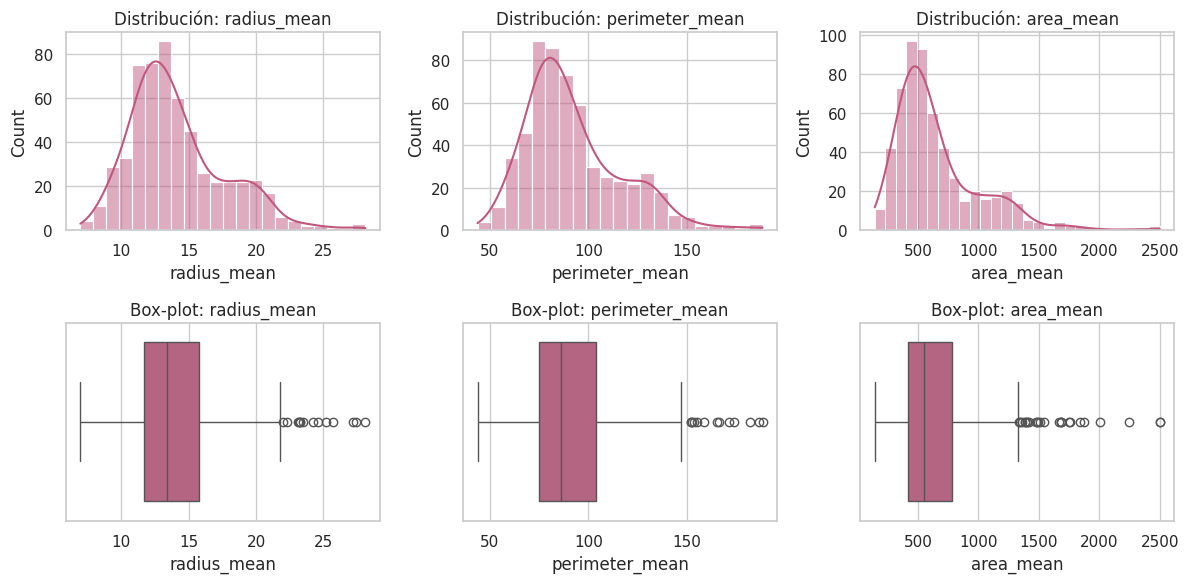

In [6]:
VARS_B1 = ["radius_mean", "perimeter_mean", "area_mean"]
hist_box(bc, VARS_B1, color="#c0587e")

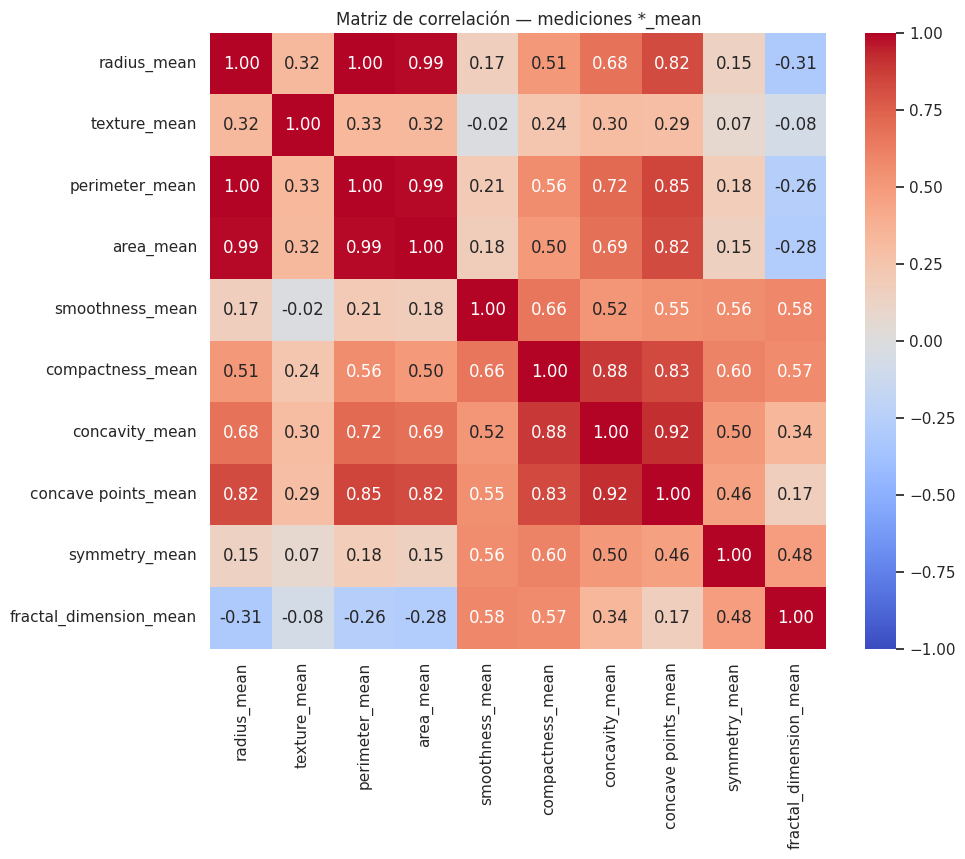

Correlación de radius_mean con el resto (todas las columnas):
perimeter_mean          0.998
area_mean               0.987
radius_worst            0.970
perimeter_worst         0.965
area_worst              0.941
concave points_mean     0.823
concave points_worst    0.744
area_se                 0.736
Name: radius_mean, dtype: float64


In [7]:
# Gráfico de correlaciones entre las 10 mediciones *_mean (las 30 columnas juntas no se alcanzan a leer)
cols_mean = [c for c in bc.columns if c.endswith("_mean")]
plt.figure(figsize=(10, 8))
sns.heatmap(bc[cols_mean].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlación — mediciones *_mean"); plt.show()

print("Correlación de radius_mean con el resto (todas las columnas):")
print(bc.corr()["radius_mean"].drop("radius_mean").sort_values(ascending=False).head(8).round(3))

### Lectura del EDA
* **Distribuciones:** las tres variables tienen asimetría positiva (cola a la derecha), y `area_mean` es la más asimétrica. Esto tiene sentido: el área crece con el cuadrado del radio, así que los núcleos grandes se "estiran" mucho más en área que en radio.
* **Box-plots:** hay valores atípicos solo en el extremo superior (núcleos muy grandes). No los elimino porque son mediciones reales, no errores de captura.
* **Correlaciones:** `radius_mean` tiene correlación casi perfecta con `perimeter_mean` (0,998) y con `area_mean` (0,987). Son las variables de mayor importancia para este ejercicio y justifican usar `radius_mean` como predictor. Las variables de textura, suavidad o simetría casi no se relacionan con el tamaño.
* Ojo: una correlación tan alta no significa que la relación sea **lineal** en los dos casos; eso lo reviso con los residuos.

## 1.3 Partición entrenamiento/prueba y modelos

In [8]:
X_b1 = bc[["radius_mean"]]
y_perim = bc["perimeter_mean"]
y_area  = bc["area_mean"]

# Misma partición (mismos índices) para ambos modelos -> comparación justa
X_tr, X_te, yp_tr, yp_te, ya_tr, ya_te = train_test_split(
    X_b1, y_perim, y_area, test_size=0.20, random_state=RANDOM_STATE)
print("Entrenamiento:", X_tr.shape[0], "filas | Prueba:", X_te.shape[0], "filas")

m_perim = LinearRegression().fit(X_tr, yp_tr)   # Modelo 1: perimeter_mean ~ radius_mean
m_area  = LinearRegression().fit(X_tr, ya_tr)   # Modelo 2: area_mean ~ radius_mean

for nombre, m in [("perimeter_mean", m_perim), ("area_mean", m_area)]:
    print(f"\nModelo {nombre} = b0 + b1 · radius_mean")
    print(f"  Pendiente (b1):  {m.coef_[0]:.4f}")
    print(f"  Intercepto (b0): {m.intercept_:.4f}")

Entrenamiento: 455 filas | Prueba: 114 filas

Modelo perimeter_mean = b0 + b1 · radius_mean
  Pendiente (b1):  6.8640
  Intercepto (b0): -5.0208

Modelo area_mean = b0 + b1 · radius_mean
  Pendiente (b1):  99.0408
  Intercepto (b0): -743.8449


### Interpretación de pendiente e intercepto
**Modelo 1 — `perimeter_mean = −5,02 + 6,86 · radius_mean`**
* **Pendiente (6,86):** por cada unidad que aumenta el radio medio, el perímetro medio aumenta en promedio 6,86 unidades de longitud. Es un valor cercano a 2π ≈ 6,28, que es lo que esperaría si los núcleos fueran círculos (P = 2πr). La diferencia se explica porque los núcleos tienen bordes irregulares, que agregan perímetro.
* **Intercepto (−5,02):** sería el perímetro para un radio de 0. No tiene sentido físico (no existe un perímetro negativo) y además está fuera del rango observado (el radio mínimo es ≈ 7). Solo sirve para ubicar la recta.

**Modelo 2 — `area_mean = −743,84 + 99,04 · radius_mean`**
* **Pendiente (99,04):** cada unidad adicional de radio se asocia, en promedio, a 99 unidades más de área. Pero geométricamente el área es πr², así que el aumento real **no es constante**: es pequeño con radios chicos y grande con radios grandes. La recta solo entrega un "promedio" de esa curva.
* **Intercepto (−743,84):** muy negativo y sin interpretación física. Es la primera señal de que una recta no describe bien esta relación: para radios cerca de 7 el modelo predice áreas casi en 0 o negativas.

## 1.4 Evaluación (R², MAE, RMSE)

In [9]:
pred_perim = m_perim.predict(X_te)
pred_area  = m_area.predict(X_te)

res_b1 = pd.DataFrame({
    "perimeter_mean (prueba)":        metricas(yp_te, pred_perim),
    "area_mean (prueba)":             metricas(ya_te, pred_area),
    "perimeter_mean (entrenamiento)": metricas(yp_tr, m_perim.predict(X_tr)),
    "area_mean (entrenamiento)":      metricas(ya_tr, m_area.predict(X_tr)),
}).T.round(3)
res_b1

,R2,MAE,RMSE
perimeter_mean (prueba),0.996,1.042,1.583
area_mean (prueba),0.981,34.975,46.578
perimeter_mean (entrenamiento),0.996,1.183,1.592
area_mean (entrenamiento),0.973,37.661,57.829


## 1.5 Visualización: recta de regresión y residuos

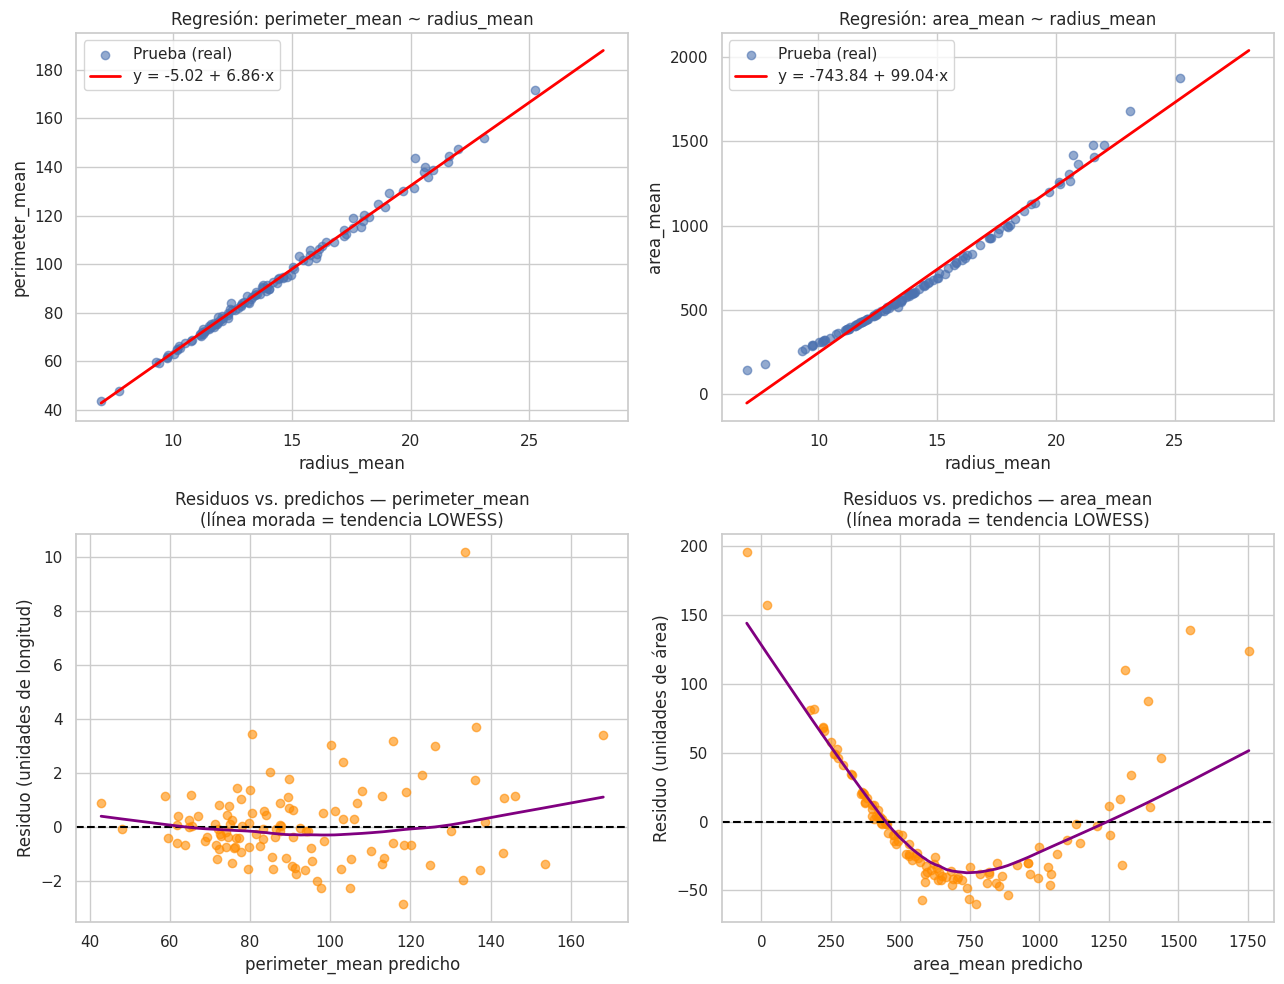

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
rango = np.linspace(X_b1["radius_mean"].min(), X_b1["radius_mean"].max(), 100).reshape(-1, 1)
rango = pd.DataFrame(rango, columns=["radius_mean"])

for j, (nombre, m, y_te_, pred, unidad) in enumerate([
        ("perimeter_mean", m_perim, yp_te, pred_perim, "unidades de longitud"),
        ("area_mean",      m_area,  ya_te, pred_area,  "unidades de área")]):
    # Recta de regresión
    ax[0, j].scatter(X_te["radius_mean"], y_te_, alpha=0.6, label="Prueba (real)")
    ax[0, j].plot(rango["radius_mean"], m.predict(rango), color="red", lw=2,
                  label=f"y = {m.intercept_:.2f} + {m.coef_[0]:.2f}·x")
    ax[0, j].set(xlabel="radius_mean", ylabel=nombre, title=f"Regresión: {nombre} ~ radius_mean")
    ax[0, j].legend()
    # Residuos vs predichos
    resid = y_te_ - pred
    ax[1, j].scatter(pred, resid, alpha=0.6, color="darkorange")
    ax[1, j].axhline(0, color="black", ls="--")
    sns.regplot(x=pred, y=resid, lowess=True, scatter=False, ax=ax[1, j], color="purple",
                line_kws={"lw": 2})
    ax[1, j].set(xlabel=f"{nombre} predicho", ylabel=f"Residuo ({unidad})",
                 title=f"Residuos vs. predichos — {nombre}\n(línea morada = tendencia LOWESS)")
plt.tight_layout(); plt.show()

### ❓ Pregunta guía: ¿un R² alto es suficiente para concluir que una recta es el modelo adecuado?
**No.** Los dos modelos tienen R² alto en prueba (0,996 el perímetro y 0,981 el área), pero los gráficos de residuos cuentan historias distintas:

* **Perímetro:** los residuos están repartidos al azar alrededor de 0, en una banda angosta (casi todos entre −3 y +3) y sin forma. La línea de tendencia (LOWESS) queda prácticamente plana. Esto confirma que la relación es lineal y la recta es adecuada, lo que coincide con la geometría (P = 2πr es una recta).
* **Área:** los residuos forman una **U** muy clara: son positivos para áreas chicas, negativos en la zona media y vuelven a ser positivos para áreas grandes. Eso significa que el modelo se equivoca de forma **sistemática**: subestima los extremos y sobreestima el centro. La relación real es cuadrática (A = πr²), y la recta solo la aproxima. Además el error crece en los núcleos grandes (RMSE ≈ 47 unidades de área frente a un MAE ≈ 35).

**Conclusión:** el R² solo dice cuánta variación explica el modelo, no si la forma del modelo es correcta. Un patrón en los residuos indica que el supuesto de linealidad no se cumple, aunque el R² sea alto. Para el área sería más adecuado usar `radius_mean²` como predictor (fuera del alcance de este laboratorio).

---
# ⚽ Bloque 2 · Regresión lineal múltiple con FIFA 19
## 2.1 Carga y limpieza

In [11]:
try:
    ruta_fifa = descargar_csv("karangadiya/fifa19", "data.csv")
except Exception as e:
    # Kaggle puede responder 403 con este dataset (permiso/consentimiento). Respaldo: copia pública
    # en GitHub del mismo archivo data.csv (18.207 filas × 89 columnas).
    print("Kaggle no disponible:", type(e).__name__, "-> uso la copia pública en GitHub")
    ruta_fifa = "https://raw.githubusercontent.com/amanthedorkknight/fifa18-all-player-statistics/master/2019/data.csv"
fifa_raw = pd.read_csv(ruta_fifa)
print("Dimensiones:", fifa_raw.shape)
fifa_raw[["Name", "Age", "Overall", "Potential", "Value", "Wage", "Position", "Height", "Weight", "Release Clause"]].head()

Kaggle no disponible: KaggleApiHTTPError -> uso la copia pública en GitHub
Dimensiones: (18207, 89)


,Name,Age,Overall,Potential,Value,Wage,Position,Height,Weight,Release Clause
0,L. Messi,31,94,94,€110.5M,€565K,RF,5'7,159lbs,€226.5M
1,Cristiano Ronaldo,33,94,94,€77M,€405K,ST,6'2,183lbs,€127.1M
2,Neymar Jr,26,92,93,€118.5M,€290K,LW,5'9,150lbs,€228.1M
3,De Gea,27,91,93,€72M,€260K,GK,6'4,168lbs,€138.6M
4,K. De Bruyne,27,91,92,€102M,€355K,RCM,5'11,154lbs,€196.4M


In [12]:
fifa = fifa_raw.copy()

# Texto -> número (se usan para revisar leakage y para el desafío opcional)
def euros(s):
    """'€110.5M' -> 110500000 ; '€565K' -> 565000 ; '€0' -> 0"""
    if pd.isna(s): return np.nan
    s = str(s).replace("€", "")
    mult = 1e6 if s.endswith("M") else 1e3 if s.endswith("K") else 1
    return float(s.rstrip("MK")) * mult

def pies_a_cm(s):
    """'5\'11' -> 180.3 cm"""
    if pd.isna(s): return np.nan
    pies, pulg = str(s).split("'")
    return round((int(pies) * 12 + int(pulg)) * 2.54, 1)

for c in ["Value", "Wage", "Release Clause"]:
    fifa[c + "_eur"] = fifa[c].apply(euros)
fifa["Height_cm"] = fifa["Height"].apply(pies_a_cm)
fifa["Weight_kg"] = (fifa["Weight"].str.replace("lbs", "").astype(float) * 0.4536).round(1)

# Filas sin posición o sin atributos (jugadores incompletos en el scraping)
antes = len(fifa)
fifa = fifa.dropna(subset=["Position", "Reactions"])
print("Filas eliminadas por datos incompletos:", antes - len(fifa), "| Filas finales:", len(fifa))

# Agrupación de posiciones (se usará para heterogeneidad)
DEF = {"CB", "LCB", "RCB", "LB", "RB", "LWB", "RWB"}
MID = {"CM", "LCM", "RCM", "CDM", "LDM", "RDM", "CAM", "LAM", "RAM", "LM", "RM"}
fifa["Grupo"] = fifa["Position"].map(lambda p: "GK" if p == "GK" else "DEF" if p in DEF else "MID" if p in MID else "FWD")
fifa["Grupo"].value_counts()

Filas eliminadas por datos incompletos: 60 | Filas finales: 18147


,count
Grupo,
MID,6838
DEF,5866
FWD,3418
GK,2025


## 2.2 EDA del ejercicio

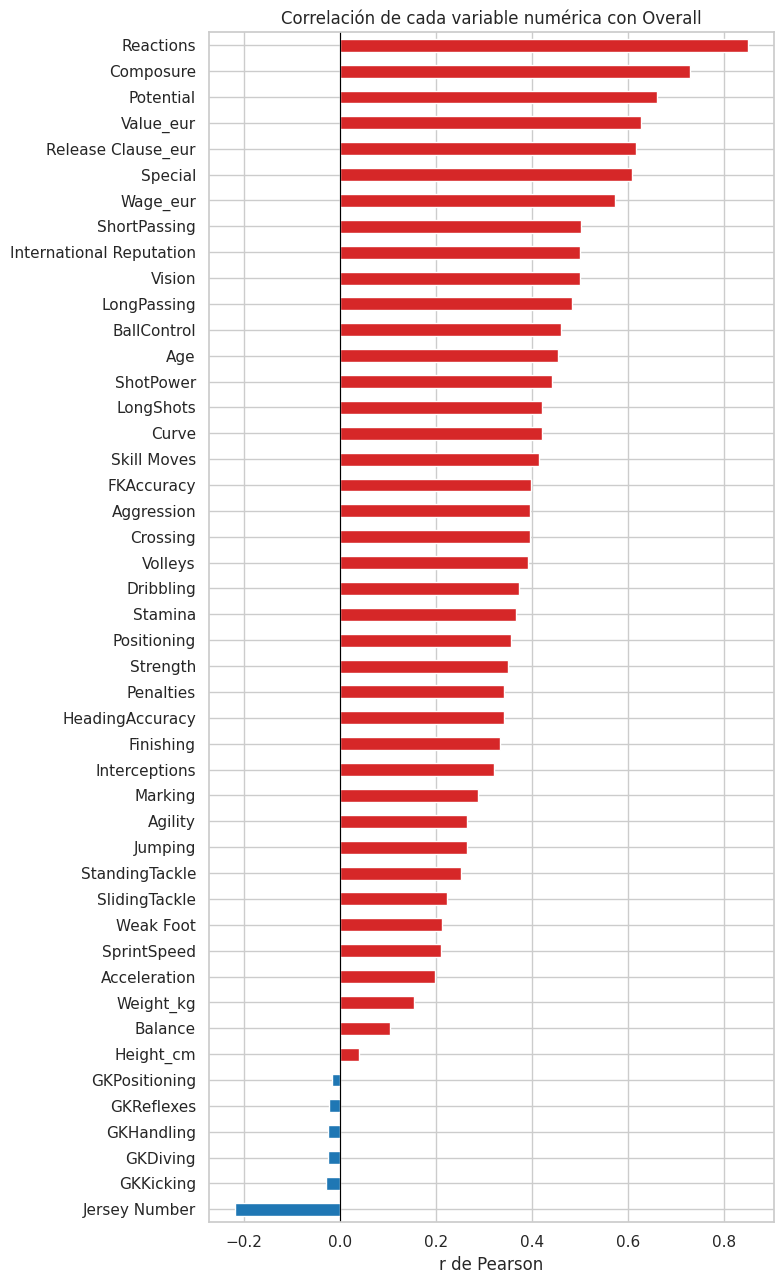

Reactions                   0.850
Composure                   0.728
Potential                   0.661
Value_eur                   0.627
Release Clause_eur          0.616
Special                     0.607
Wage_eur                    0.572
ShortPassing                0.502
International Reputation    0.500
Vision                      0.499
LongPassing                 0.484
BallControl                 0.460
Age                         0.453
ShotPower                   0.441
LongShots                   0.421
Name: Overall, dtype: float64


In [13]:
num_fifa = fifa.select_dtypes("number").drop(columns=["Unnamed: 0", "ID"])
corr_overall = num_fifa.corr()["Overall"].drop("Overall").sort_values()

plt.figure(figsize=(8, 13))
colores = ["#d62728" if v > 0 else "#1f77b4" for v in corr_overall]
corr_overall.plot(kind="barh", color=colores)
plt.axvline(0, color="black", lw=0.8)
plt.title("Correlación de cada variable numérica con Overall"); plt.xlabel("r de Pearson")
plt.tight_layout(); plt.show()
print(corr_overall.sort_values(ascending=False).head(15).round(3))

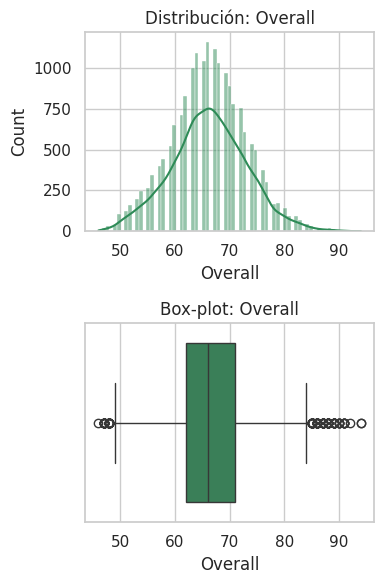

In [14]:
hist_box(fifa, ["Overall"], color="seagreen")

### Lectura del EDA
* **Overall** tiene una distribución muy cercana a la normal (simétrica, centrada en ≈ 66 puntos). El box-plot muestra pocos atípicos en ambos extremos (las estrellas sobre 85 y algunos juveniles bajo 50).
* En el gráfico de correlaciones las variables más relacionadas con `Overall` son **Reactions (0,85)** y **Composure (0,73)**, seguidas por Potential, Value, Release Clause, Special y Wage. Varias de estas últimas no se pueden usar (ver control de leakage).
* Los atributos de arquero (`GKDiving`, `GKReflexes`, etc.) tienen correlación ≈ 0 con Overall. No es que no importen: son altísimos en arqueros y bajísimos en el resto, y al mezclar ambos grupos se anulan. Es una primera pista de **heterogeneidad**.

## 2.3 Selección de predictores: control de data leakage

### Pregunta de control de leakage aplicada a cada variable
*«¿Existiría esta variable antes de conocer Overall? ¿Se calcula a partir de él o ambos vienen de la misma fuente?»*

| Variable | ¿Se usa? | Justificación |
| :--- | :---: | :--- |
| `Potential` | ❌ | Es la proyección del Overall a futuro; siempre es ≥ Overall y se construye a partir de él. |
| `Value`, `Wage`, `Release Clause` | ❌ | Son **consecuencia** de la valoración: un jugador vale y gana más porque tiene mejor Overall. `Release Clause` además se calcula a partir de `Value`. |
| `International Reputation` | ❌ | Sale de la misma fuente (la trayectoria y nivel del jugador) y se actualiza según su valoración. |
| `Special` | ❌ | Es la **suma** de los atributos del jugador; mezcla la misma información que define el Overall en un solo número. |
| Valoraciones por posición (`LS`, `ST`, `CAM`, `CB`, …) | ❌ | Son el Overall recalculado para cada posición (texto tipo "88+2"). Son prácticamente la variable objetivo. |
| `ID`, `Unnamed: 0`, `Jersey Number` | ❌ | Identificadores o números de camiseta, sin relación lógica con el nivel del jugador. |
| Atributos técnicos y físicos (`Reactions`, `Composure`, `ShortPassing`, `Vision`, `Strength`, …), `Age`, `Height_cm` | ✅ | Existen antes del Overall: son las mediciones de habilidad a partir de las cuales se evalúa al jugador. No son una consecuencia de él. |

De los atributos válidos tomo **12 candidatas**: las 7 con mayor correlación (Reactions, Composure, ShortPassing, Vision, LongPassing, BallControl, Age) y 5 que representan otras dimensiones del juego (Dribbling, Stamina, Strength, HeadingAccuracy y Height_cm, esta última para tener una variable física con unidades en cm).

In [15]:
LEAKAGE = ["Potential", "Special", "International Reputation", "Value_eur", "Wage_eur", "Release Clause_eur"]
NO_PREDICTIVAS = ["Unnamed: 0", "ID", "Jersey Number"]

CANDIDATAS = ["Reactions", "Composure", "ShortPassing", "Vision", "LongPassing", "BallControl",
              "Dribbling", "Age", "Strength", "Stamina", "HeadingAccuracy", "Height_cm"]
print("Correlación con Overall de las candidatas:")
print(fifa[CANDIDATAS].corrwith(fifa["Overall"]).sort_values(ascending=False).round(3))

Correlación con Overall de las candidatas:
Reactions          0.850
Composure          0.728
ShortPassing       0.502
Vision             0.499
LongPassing        0.484
BallControl        0.460
Age                0.453
Dribbling          0.372
Stamina            0.366
Strength           0.349
HeadingAccuracy    0.341
Height_cm          0.039
dtype: float64


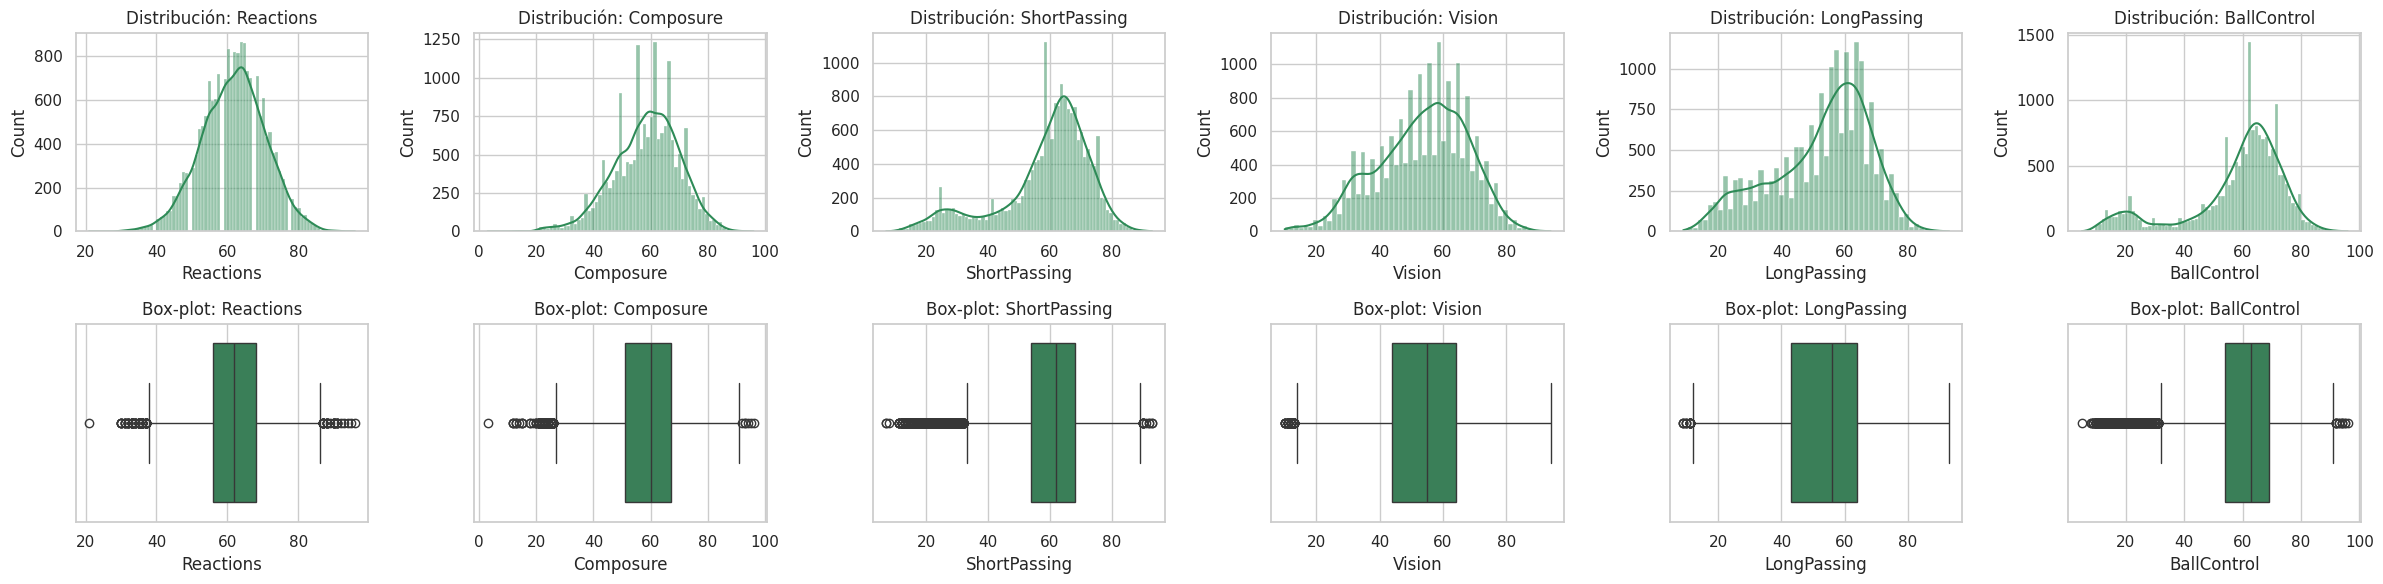

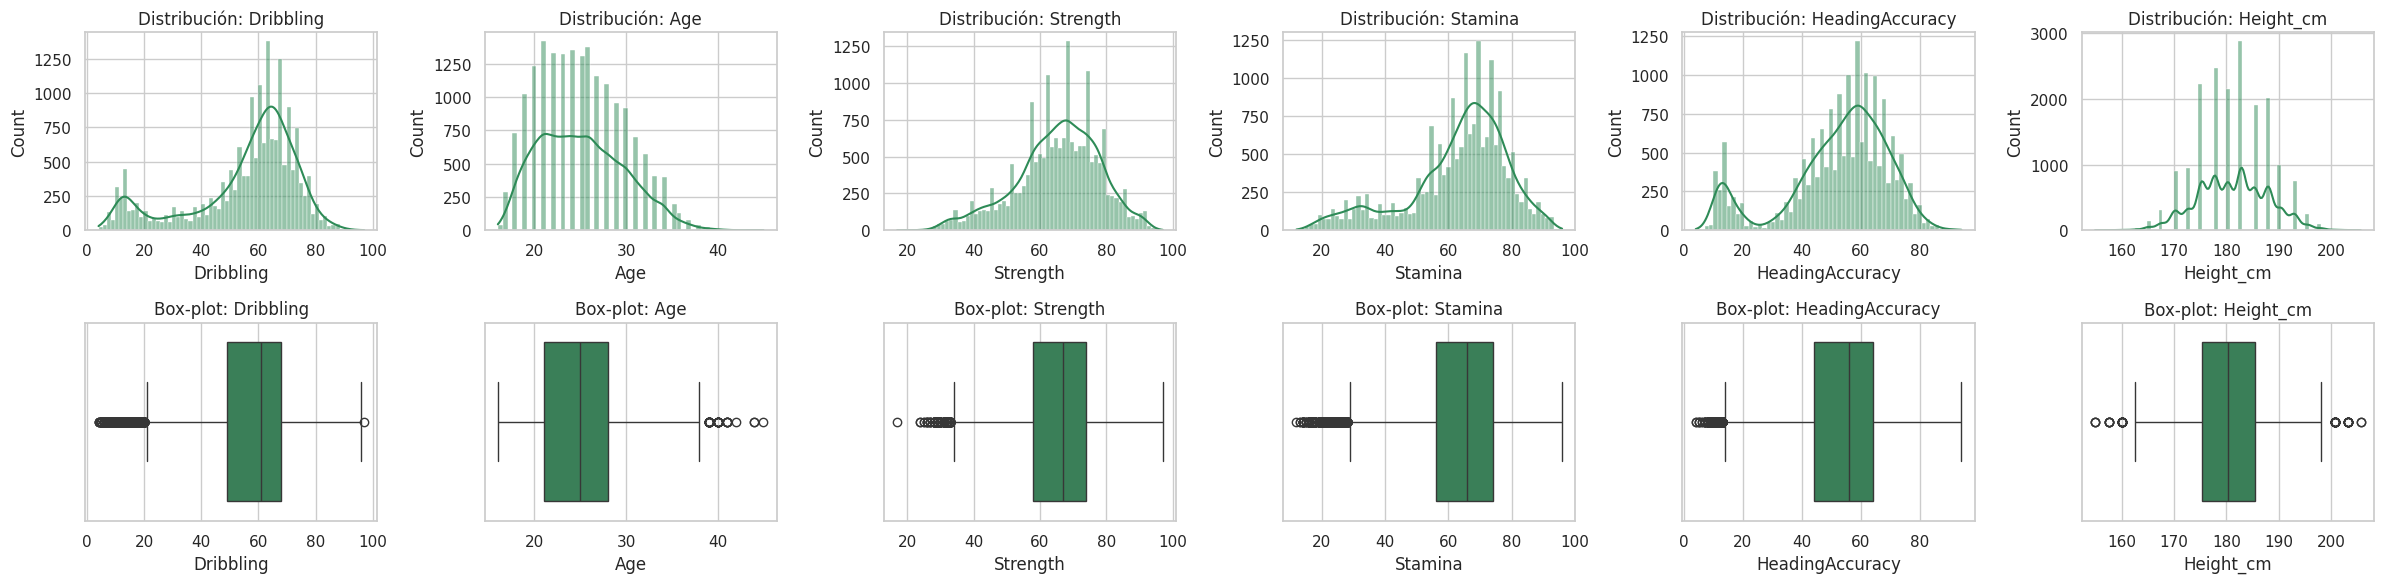

In [16]:
hist_box(fifa, CANDIDATAS[:6], color="seagreen")
hist_box(fifa, CANDIDATAS[6:], color="seagreen")

## 2.4 Multicolinealidad: correlación entre predictores y VIF

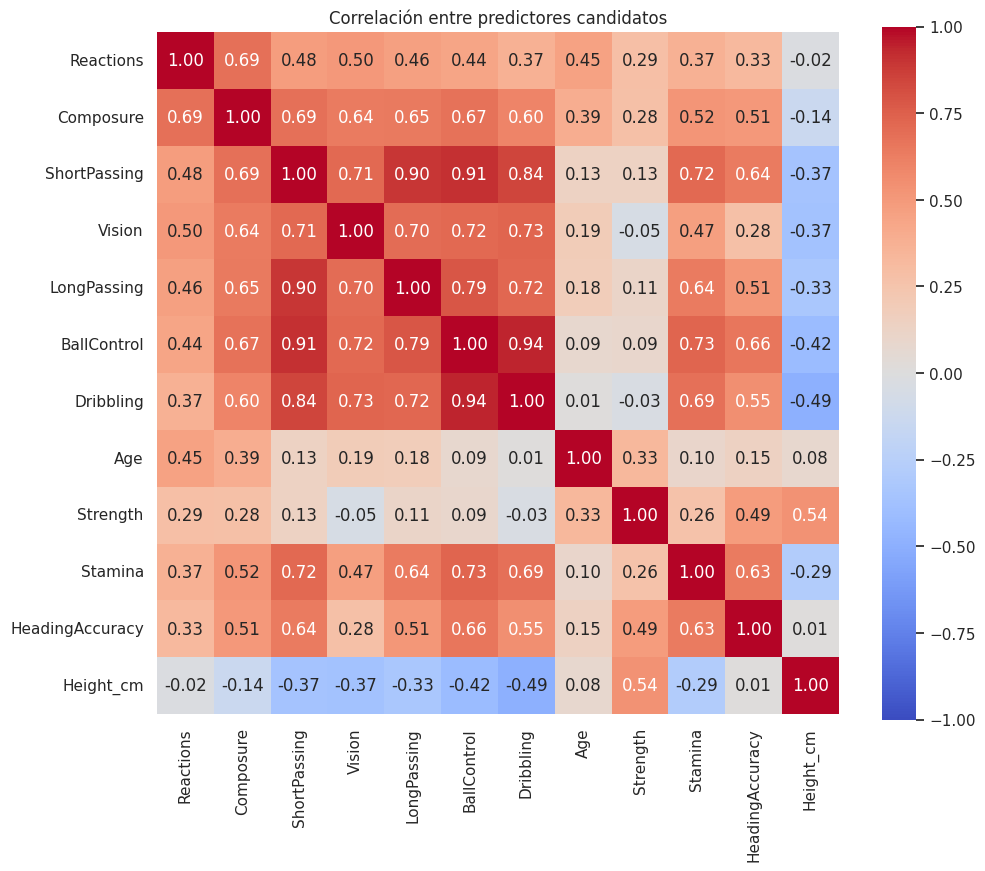

VIF con las 12 candidatas:


,variable,VIF
0,BallControl,17.01
1,ShortPassing,12.32
2,Dribbling,10.93
3,LongPassing,5.69
4,Vision,3.32
5,HeadingAccuracy,3.25
6,Composure,3.21
7,Stamina,2.67
8,Strength,2.55
9,Height_cm,2.26


In [17]:
plt.figure(figsize=(11, 9))
sns.heatmap(fifa[CANDIDATAS].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlación entre predictores candidatos"); plt.show()

print("VIF con las 12 candidatas:")
tabla_vif(fifa[CANDIDATAS]).round(2)

In [18]:
# Decisión: se eliminan las variables redundantes (ver justificación abajo)
ELIMINADAS_VIF = ["BallControl", "Dribbling", "LongPassing"]
PREDICTORES_B2 = [c for c in CANDIDATAS if c not in ELIMINADAS_VIF]
print("Predictores finales:", PREDICTORES_B2)
tabla_vif(fifa[PREDICTORES_B2]).round(2)

Predictores finales: ['Reactions', 'Composure', 'ShortPassing', 'Vision', 'Age', 'Strength', 'Stamina', 'HeadingAccuracy', 'Height_cm']


,variable,VIF
0,ShortPassing,4.77
1,Composure,3.11
2,HeadingAccuracy,2.77
3,Vision,2.73
4,Stamina,2.53
5,Strength,2.50
6,Reactions,2.15
7,Height_cm,2.13
8,Age,1.44


### Decisión sobre multicolinealidad
* En la matriz de correlación, `BallControl`, `Dribbling` y `ShortPassing` están muy correlacionadas entre sí (r entre 0,84 y 0,94): miden casi lo mismo, el manejo técnico del balón.
* El VIF lo confirma: **BallControl (17,0)**, **ShortPassing (12,3)** y **Dribbling (10,9)** superan el umbral de 10, y **LongPassing (5,7)** está en zona de alerta.
* **Elimino `BallControl` y `Dribbling`** (las más redundantes) y **`LongPassing`**, que repite la información de `ShortPassing`. Mantengo `ShortPassing` porque es la que tiene mayor correlación con Overall dentro de ese grupo.
* Después de eliminarlas **todos los VIF quedan bajo 5** (el máximo es ShortPassing con 4,8), así que los coeficientes del modelo se pueden interpretar con estabilidad. Quedan **9 predictores**.

## 2.5 Modelo y métricas

In [19]:
X_b2 = fifa[PREDICTORES_B2]
y_b2 = fifa["Overall"]
X2_tr, X2_te, y2_tr, y2_te = train_test_split(X_b2, y_b2, test_size=0.20, random_state=RANDOM_STATE)

m_b2 = LinearRegression().fit(X2_tr, y2_tr)
pred2_tr, pred2_te = m_b2.predict(X2_tr), m_b2.predict(X2_te)

display(pd.DataFrame({"Entrenamiento": metricas(y2_tr, pred2_tr),
                      "Prueba":        metricas(y2_te, pred2_te)}).T.round(3))

coef_b2 = pd.DataFrame({"coeficiente": m_b2.coef_}, index=PREDICTORES_B2).sort_values("coeficiente", ascending=False)
print(f"Intercepto: {m_b2.intercept_:.3f}")
coef_b2.round(4)

,R2,MAE,RMSE
Entrenamiento,0.780,2.564,3.252
Prueba,0.777,2.541,3.226


Intercepto: 8.727


,coeficiente
Reactions,0.4723
Composure,0.1528
Height_cm,0.0765
Age,0.0541
Strength,0.0523
ShortPassing,0.0520
Vision,0.0072
Stamina,-0.0101
HeadingAccuracy,-0.0397


### Métricas e interpretación de coeficientes
* **Métricas:** R² = 0,780 en entrenamiento y 0,777 en prueba; MAE ≈ 2,5 puntos y RMSE ≈ 3,2 puntos en ambos conjuntos. La diferencia entre entrenamiento y prueba es mínima, así que el modelo **no está sobreajustado**: se equivoca en promedio unos 2,5 puntos de Overall, en una escala donde la mayoría de los jugadores está entre 60 y 75.

Interpretación (cada coeficiente supone que el resto de las variables se mantiene constante):
1. **Reactions = 0,472 puntos de Overall por punto de Reactions.** Es el predictor más fuerte: un jugador con 10 puntos más de Reactions tiene en promedio ≈ 4,7 puntos más de Overall.
2. **Composure = 0,153 puntos de Overall por punto de Composure.** La tranquilidad bajo presión también suma, pero tres veces menos que Reactions.
3. **Height_cm = 0,077 puntos de Overall por cada cm de estatura.** Un jugador 10 cm más alto tiene, con iguales atributos, ≈ 0,8 puntos más de Overall.
4. **Age = 0,054 puntos de Overall por año.** A igualdad de atributos, los jugadores mayores tienen una valoración levemente más alta (experiencia).
5. **HeadingAccuracy = −0,040:** el signo negativo no significa que cabecear bien "baje" el Overall. Refleja la mezcla de posiciones: los arqueros tienen cabezazo muy bajo y aun así un Overall alto, lo que arrastra el coeficiente. Es otro indicio de heterogeneidad.

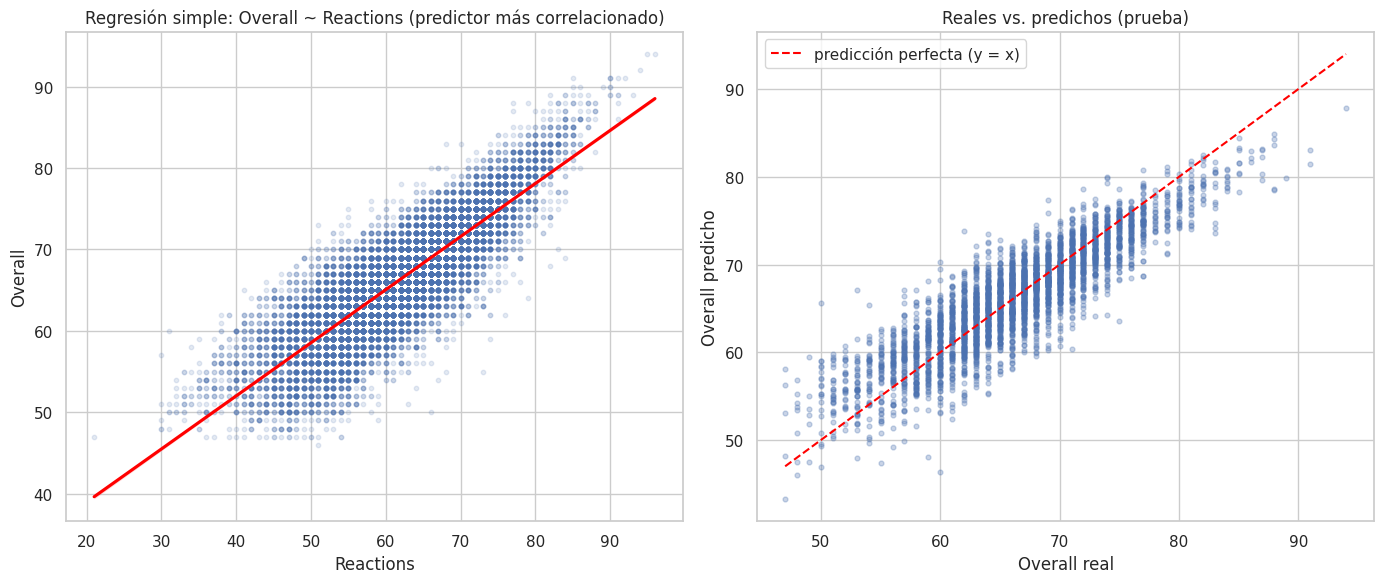

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
mejor = fifa[PREDICTORES_B2].corrwith(fifa["Overall"]).idxmax()
sns.regplot(data=fifa, x=mejor, y="Overall", ax=ax[0], scatter_kws={"alpha": 0.15, "s": 10},
            line_kws={"color": "red"})
ax[0].set_title(f"Regresión simple: Overall ~ {mejor} (predictor más correlacionado)")

ax[1].scatter(y2_te, pred2_te, alpha=0.3, s=12)
lims = [y2_te.min(), y2_te.max()]
ax[1].plot(lims, lims, color="red", ls="--", label="predicción perfecta (y = x)")
ax[1].set(xlabel="Overall real", ylabel="Overall predicho", title="Reales vs. predichos (prueba)")
ax[1].legend(); plt.tight_layout(); plt.show()

## 2.6 Heterogeneidad: métricas por subgrupo de jugadores

,n,R2,MAE,RMSE,Residuo medio (sesgo)
Grupo,,,,,
GK,407,0.730,3.199,3.983,1.256
DEF,1157,0.802,2.258,2.849,0.414
MID,1386,0.752,2.651,3.347,-0.586
FWD,680,0.813,2.405,3.067,-0.272
GLOBAL,3630,0.777,2.541,3.226,-0.002


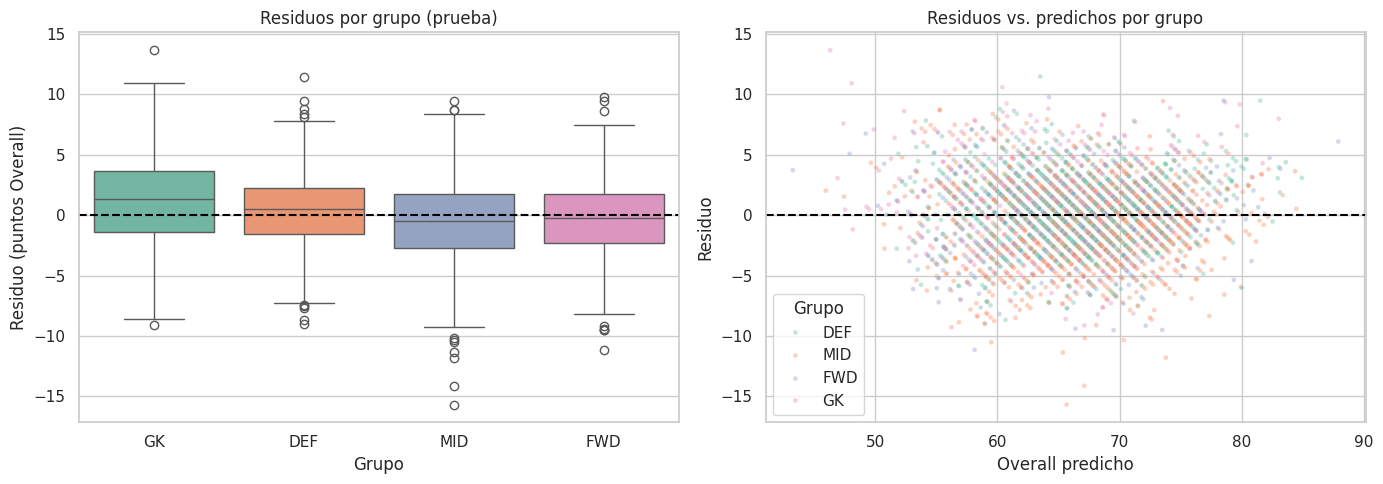

In [21]:
grupos_te = fifa.loc[X2_te.index, "Grupo"]
resid2_te = y2_te - pred2_te

filas = []
for g in ["GK", "DEF", "MID", "FWD"]:
    i = grupos_te == g
    filas.append({"Grupo": g, "n": int(i.sum()), **metricas(y2_te[i], pred2_te[i]),
                  "Residuo medio (sesgo)": resid2_te[i].mean()})
filas.append({"Grupo": "GLOBAL", "n": len(y2_te), **metricas(y2_te, pred2_te), "Residuo medio (sesgo)": resid2_te.mean()})
het_b2 = pd.DataFrame(filas).set_index("Grupo").round(3)
display(het_b2)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=grupos_te, y=resid2_te, order=["GK", "DEF", "MID", "FWD"], ax=ax[0], palette="Set2")
ax[0].axhline(0, color="black", ls="--"); ax[0].set(title="Residuos por grupo (prueba)", xlabel="Grupo", ylabel="Residuo (puntos Overall)")
sns.scatterplot(x=pred2_te, y=resid2_te, hue=grupos_te, alpha=0.4, s=12, ax=ax[1], palette="Set2")
ax[1].axhline(0, color="black", ls="--"); ax[1].set(title="Residuos vs. predichos por grupo", xlabel="Overall predicho", ylabel="Residuo")
plt.tight_layout(); plt.show()

### Comentario comparativo por subgrupo
Agrupé las posiciones en **GK** (arqueros), **DEF** (defensas y laterales), **MID** (mediocampistas) y **FWD** (delanteros y extremos).

* El modelo global tiene un sesgo prácticamente nulo (residuo medio ≈ 0), pero al separar por grupo aparece un **error sistemático**:
  * **GK:** es el peor grupo (MAE ≈ 3,2; R² = 0,73) y tiene un residuo medio de **+1,26**, es decir, el modelo **subestima** a los arqueros. Tiene lógica: el Overall de un arquero depende de los atributos `GK*`, que no están en el modelo, y sus atributos de campo (pase, cabezazo, resistencia) son bajos.
  * **MID:** residuo medio de **−0,59**, el modelo los **sobreestima** un poco. Los mediocampistas suelen tener buenos valores de pase y visión, y el modelo les da más Overall del que realmente tienen.
  * **DEF y FWD** son los grupos mejor descritos (R² ≈ 0,80 y 0,81; MAE ≈ 2,3–2,4).
* En el box-plot de residuos la mediana de los arqueros queda claramente sobre 0, mientras que la de MID queda bajo 0.

**Conclusión:** una sola recta para todos los jugadores esconde que funciona distinto según la posición. El MAE global (2,5) parece aceptable, pero para los arqueros el error es casi un 30 % mayor. Sería más correcto entrenar un modelo separado para arqueros (con los atributos `GK*`) o agregar la posición como predictor.

## 2.7 Desafío opcional: predecir `Value`

Jugadores con valor > 0: 17907


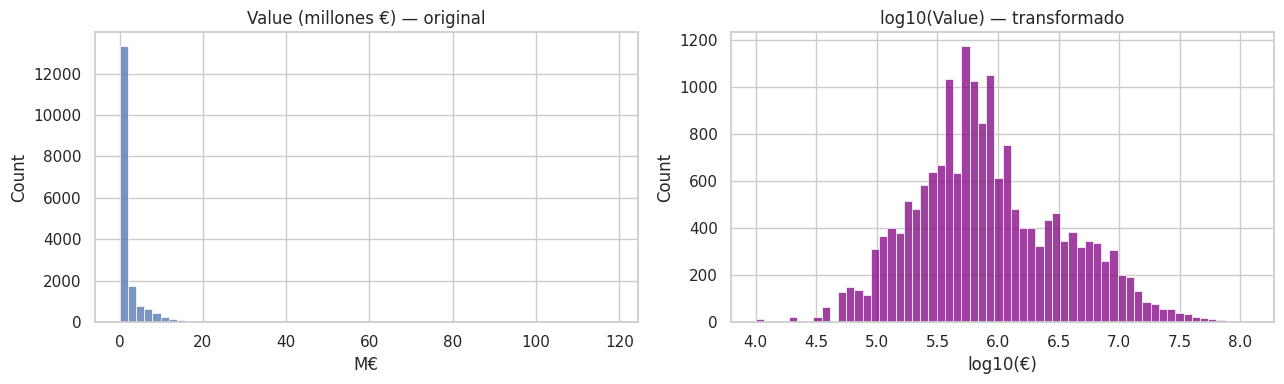

,R2,MAE (M€),RMSE (M€)
Value directo,0.450,2.164,4.332
log10(Value) → €,0.705,0.578,3.174


Predicciones negativas del modelo directo: 888 de 3582


In [22]:
val = fifa[fifa["Value_eur"] > 0].copy()          # valor 0 = jugadores sin tasación
val["log_Value"] = np.log10(val["Value_eur"])
print("Jugadores con valor > 0:", len(val))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(val["Value_eur"] / 1e6, bins=60, ax=ax[0]); ax[0].set(title="Value (millones €) — original", xlabel="M€")
sns.histplot(val["log_Value"], bins=60, ax=ax[1], color="purple"); ax[1].set(title="log10(Value) — transformado", xlabel="log10(€)")
plt.tight_layout(); plt.show()

# Para predecir Value, Overall y Potential SÍ son predictores válidos (existen antes de tasar al jugador).
# Wage y Release Clause se excluyen: se fijan a partir del valor (fuga).
PRED_VALUE = ["Overall", "Potential", "Age"]
Xv_tr, Xv_te, yv_tr, yv_te = train_test_split(val[PRED_VALUE], val["Value_eur"], test_size=0.20, random_state=RANDOM_STATE)

m_lin = LinearRegression().fit(Xv_tr, yv_tr)
m_log = LinearRegression().fit(Xv_tr, np.log10(yv_tr))
pred_lin = m_lin.predict(Xv_te)
pred_log = 10 ** m_log.predict(Xv_te)               # se vuelve a euros para comparar en la misma escala

comp = pd.DataFrame({"Value directo": metricas(yv_te, pred_lin),
                     "log10(Value) → €": metricas(yv_te, pred_log)}).T
comp["MAE"] /= 1e6; comp["RMSE"] /= 1e6
comp.columns = ["R2", "MAE (M€)", "RMSE (M€)"]
display(comp.round(3))
print("Predicciones negativas del modelo directo:", int((pred_lin < 0).sum()), "de", len(pred_lin))

### Desafío opcional: resultado
* `Value` venía como texto (`€110.5M`, `€565K`) y lo convertí a euros. Su distribución es **extremadamente asimétrica**: la gran mayoría de los jugadores vale menos de 5 M€ y unos pocos superan los 100 M€. Al aplicar `log10` la distribución queda casi simétrica.
* Predictores usados: `Overall`, `Potential` y `Age`. Aquí sí son válidos, porque la valoración deportiva existe **antes** de fijar el valor de mercado. Excluí `Wage` y `Release Clause` porque se definen a partir del valor (fuga).
* **Comparación en euros sobre el conjunto de prueba:** el modelo directo obtiene R² = 0,45 y MAE ≈ 2,2 M€, y además entrega **888 valores negativos** (precios imposibles). El modelo con `log10(Value)` sube a **R² = 0,71** y baja el MAE a ≈ 0,58 M€.
* **Conclusión:** la transformación logarítmica mejora mucho el modelo porque el valor crece de forma exponencial con el Overall (un punto más de Overall en una estrella vale muchos más millones que en un jugador promedio). En escala log esa relación se vuelve casi lineal.

---
# 🚀 Bloque 3 · Transferencia a mi dataset: Telco Customer Churn
Retomo el dataset del Laboratorio 01 / Evaluación Unidad 1 (*Telco Customer Churn*, IBM / Kaggle). Ahí la variable objetivo era `Churn` (categórica); para regresión lineal necesito una variable **numérica continua**, así que elijo **`MonthlyCharges`** (cargo mensual en dólares).

**Pregunta de negocio:** ¿cuánto se le cobra mensualmente a un cliente según los servicios que tiene contratados? ¿La tarifa se explica bien con una recta (modelo aditivo)?

In [23]:
try:
    ruta_telco = descargar_csv("blastchar/telco-customer-churn")
except Exception as e:   # respaldo: copia pública de IBM (mismo archivo)
    print("Kaggle no disponible:", e, "-> uso la copia pública de IBM")
    ruta_telco = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
telco = pd.read_csv(ruta_telco)
print("Dimensiones:", telco.shape)
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce")
print("Nulos:"); print(telco.isnull().sum()[telco.isnull().sum() > 0])
telco.head()

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Descargado en: /kaggle/input/telco-customer-churn
Archivos CSV: ['WA_Fn-UseC_-Telco-Customer-Churn.csv']
CSV principal: WA_Fn-UseC_-Telco-Customer-Churn.csv
Dimensiones: (7043, 21)
Nulos:
TotalCharges    11
dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3.1 Control de data leakage antes de modelar

In [24]:
# Evidencia: TotalCharges se calcula a partir de MonthlyCharges (≈ MonthlyCharges × tenure)
t = telco.dropna(subset=["TotalCharges"])
r = np.corrcoef(t["TotalCharges"], t["MonthlyCharges"] * t["tenure"])[0, 1]
print(f"Correlación TotalCharges vs (MonthlyCharges × tenure): {r:.4f}")

Correlación TotalCharges vs (MonthlyCharges × tenure): 0.9996


### Variables excluidas por leakage o por no ser predictivas
| Variable | Decisión | Justificación |
| :--- | :---: | :--- |
| `TotalCharges` | ❌ | Se **calcula a partir de la variable objetivo**: su correlación con `MonthlyCharges × tenure` es 0,9996. Es el mismo caso que «precio por m²» al predecir el precio de una vivienda. |
| `Churn` | ❌ | Ocurre **después** del cobro: cuando se fija la tarifa todavía no se sabe si el cliente se va a ir. Además, en la Unidad 1 vimos que los cargos altos influyen en la fuga, así que sería usar un efecto para predecir su causa. |
| `customerID` | ❌ | Identificador alfanumérico sin información. |
| `PaymentMethod` | ❌ | Es la forma de pago, no lo que se cobra. No hay razón de negocio para que cambie el monto que se cobra. |
| Servicios contratados (`PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) | ✅ | Se conocen **antes** de emitir la factura: el cliente los contrata y la empresa cobra según ellos. |
| `tenure`, `Contract`, demográficas | ⚠️ | Existen antes del cobro (no hay fuga), pero las evalúo con la correlación antes de incluirlas. |

## 3.2 Codificación de variables

In [25]:
# Codificación determinista (un mapeo fijo, sin "ajustar" nada a los datos), por eso puede hacerse
# antes de la partición sin generar fuga. Si usara un escalador, lo ajustaría SOLO con entrenamiento.
SERVICIOS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
             "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
tel = pd.DataFrame(index=telco.index)
for c in SERVICIOS:                                  # 'Yes' = 1 ; 'No' / 'No internet service' / 'No phone service' = 0
    tel[c] = (telco[c] == "Yes").astype(int)
tel["Fiber"] = (telco["InternetService"] == "Fiber optic").astype(int)   # categoría base: sin internet
tel["DSL"]   = (telco["InternetService"] == "DSL").astype(int)
for c in ["Partner", "Dependents", "PaperlessBilling"]:
    tel[c] = (telco[c] == "Yes").astype(int)
tel["SeniorCitizen"] = telco["SeniorCitizen"]
tel["Male"]          = (telco["gender"] == "Male").astype(int)
tel["tenure"]        = telco["tenure"]
tel["OneYear"]       = (telco["Contract"] == "One year").astype(int)  # base: mes a mes
tel["TwoYear"]       = (telco["Contract"] == "Two year").astype(int)
tel["MonthlyCharges"] = telco["MonthlyCharges"]
# Variable SOLO para el EDA (no entra al modelo: es la suma de otros predictores)
tel["n_servicios"] = tel[SERVICIOS].sum(axis=1) + (telco["InternetService"] != "No").astype(int)
tel.head()

,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Fiber,DSL,Partner,Dependents,PaperlessBilling,SeniorCitizen,Male,tenure,OneYear,TwoYear,MonthlyCharges,n_servicios
0,0,0,0,1,0,0,0,0,0,1,1,0,1,0,0,1,0,0,29.85,2
1,1,0,1,0,1,0,0,0,0,1,0,0,0,0,1,34,1,0,56.95,4
2,1,0,1,1,0,0,0,0,0,1,0,0,1,0,1,2,0,0,53.85,4
3,0,0,1,0,1,1,0,0,0,1,0,0,0,0,1,45,1,0,42.30,4
4,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,2,0,0,70.70,2


## 3.3 EDA del ejercicio

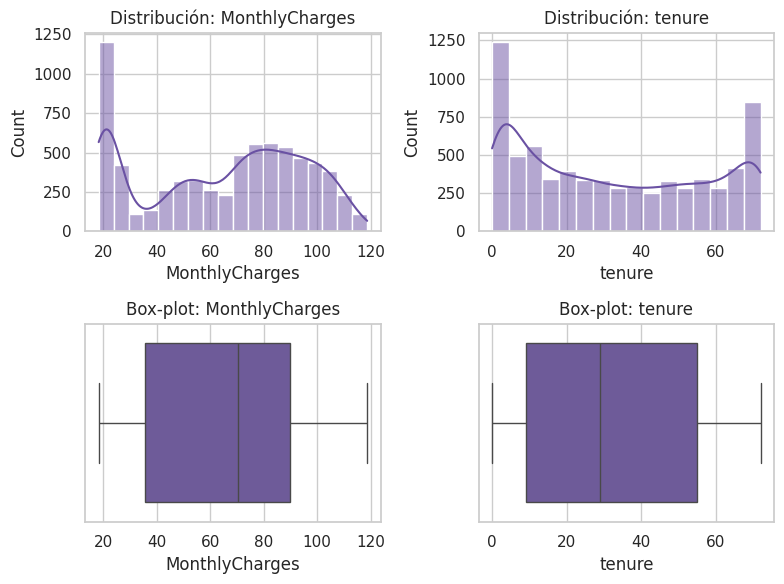

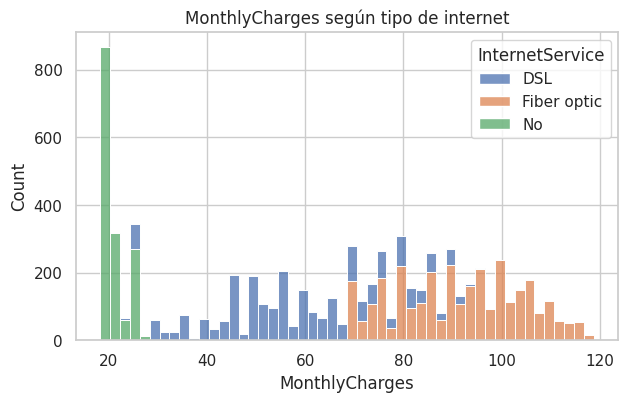

In [26]:
hist_box(tel.assign(InternetService=telco["InternetService"]), ["MonthlyCharges", "tenure"], color="#6a51a3")

plt.figure(figsize=(7, 4))
sns.histplot(data=telco, x="MonthlyCharges", hue="InternetService", bins=50, multiple="stack")
plt.title("MonthlyCharges según tipo de internet"); plt.show()

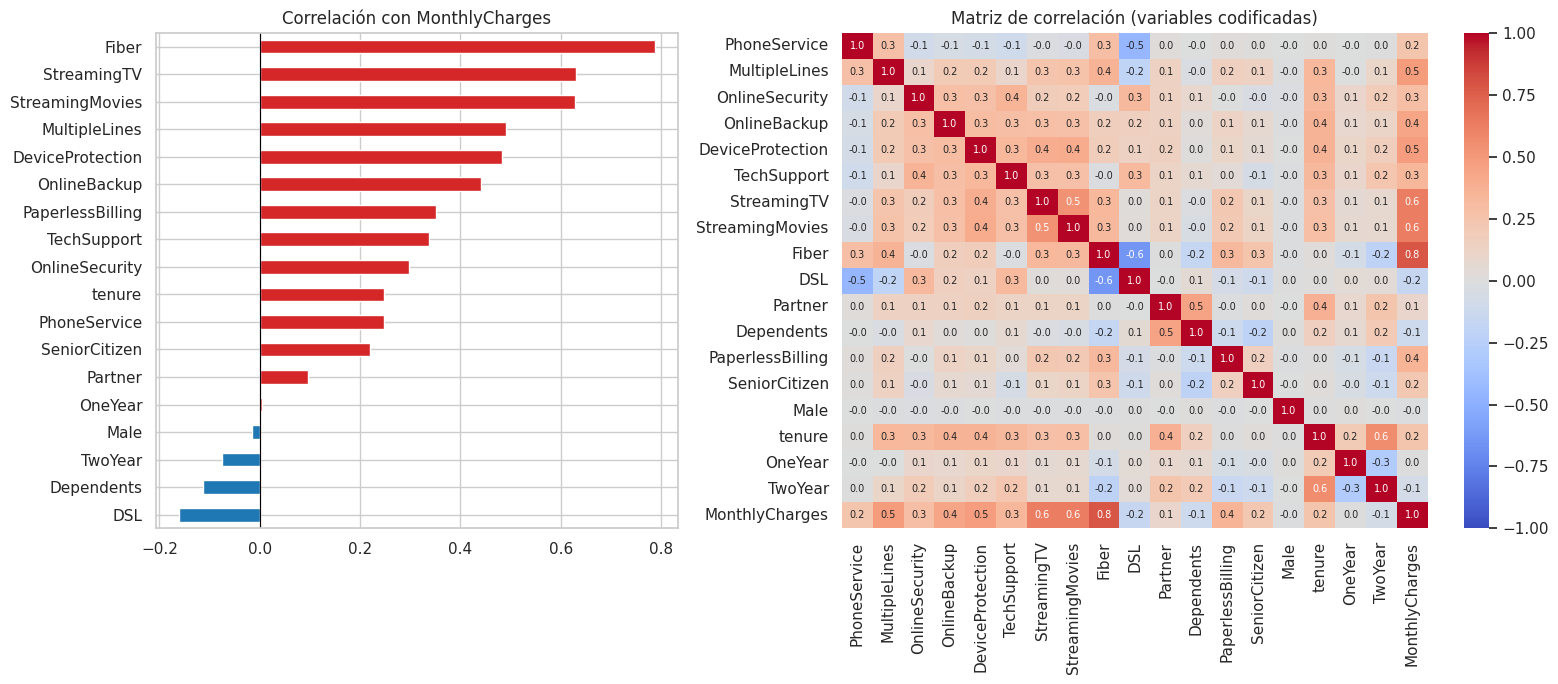

In [27]:
corr_mc = tel.drop(columns=["n_servicios"]).corr()["MonthlyCharges"].drop("MonthlyCharges").sort_values()
fig, ax = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.4]})
corr_mc.plot(kind="barh", ax=ax[0], color=["#d62728" if v > 0 else "#1f77b4" for v in corr_mc])
ax[0].axvline(0, color="black", lw=0.8); ax[0].set_title("Correlación con MonthlyCharges")
sns.heatmap(tel.drop(columns=["n_servicios"]).corr(), cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1], annot=True, fmt=".1f", annot_kws={"size": 7})
ax[1].set_title("Matriz de correlación (variables codificadas)")
plt.tight_layout(); plt.show()

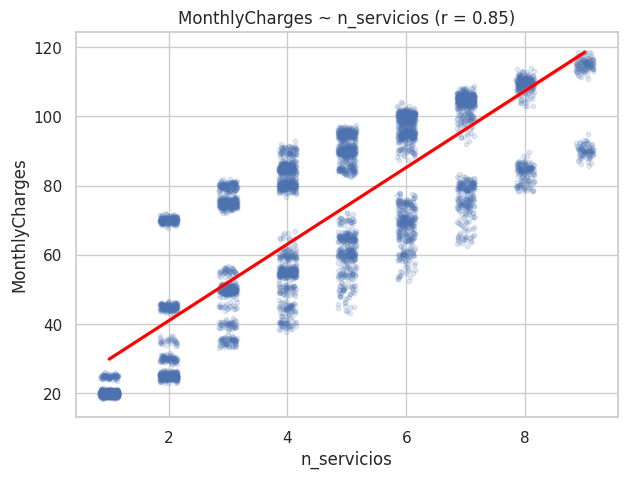

In [28]:
# Gráfico de regresión exploratorio con su línea: cargo mensual vs. número de servicios contratados
plt.figure(figsize=(7, 5))
sns.regplot(data=tel, x="n_servicios", y="MonthlyCharges", x_jitter=0.15,
            scatter_kws={"alpha": 0.15, "s": 10}, line_kws={"color": "red"})
plt.title(f"MonthlyCharges ~ n_servicios (r = {tel['n_servicios'].corr(tel['MonthlyCharges']):.2f})"); plt.show()

### Lectura del EDA
* **Distribución de `MonthlyCharges`:** no es normal, es **bimodal**. Hay un peak cerca de 20 USD y otra masa entre 70 y 105 USD. El histograma por tipo de internet explica el motivo: el peak de 20 USD son los clientes **sin internet** (solo teléfono), y los cargos más altos corresponden a **fibra óptica**. El box-plot no muestra atípicos (todo está entre ≈ 18 y 119 USD).
* **`tenure`** se distribuye en forma de U: muchos clientes nuevos y muchos de larga permanencia.
* **Correlaciones:** las variables de mayor importancia son `Fiber` (0,79), `StreamingTV` y `StreamingMovies` (0,63), `MultipleLines` (0,49), `DeviceProtection` (0,48) y `OnlineBackup` (0,44). Es decir, **todas son servicios contratados**.
* Las variables demográficas (`Male`, `Partner`, `Dependents`) y el tipo de contrato tienen correlaciones cercanas a 0, por lo que no las incluyo. `tenure` (0,25), `PaperlessBilling` (0,35) y `SeniorCitizen` (0,22) tienen algo de correlación, pero no hay una razón de negocio para que cambien la tarifa: lo más probable es que estén asociadas a que esos clientes contratan más servicios. Lo verifico después del modelo.
* El gráfico de regresión exploratorio muestra que el cargo sube con la cantidad de servicios contratados (r = 0,78), pero con mucha dispersión, porque no todos los servicios cuestan lo mismo.

## 3.4 Selección de predictores y multicolinealidad

In [29]:
PREDICTORES_B3 = SERVICIOS + ["Fiber", "DSL"]
print("VIF de los predictores elegidos:")
display(tabla_vif(tel[PREDICTORES_B3]).round(2))

# ¿Qué pasaría con una codificación ingenua (get_dummies de cada servicio con sus 3 categorías)?
ingenua = pd.get_dummies(telco[["InternetService", "OnlineSecurity", "TechSupport"]], drop_first=False, dtype=int)
print("Codificación ingenua: columnas", list(ingenua.columns))
print("¿OnlineSecurity_No internet service == InternetService_No en todas las filas?",
      (ingenua["OnlineSecurity_No internet service"] == ingenua["InternetService_No"]).all())

VIF de los predictores elegidos:


,variable,VIF
0,DSL,2.74
1,Fiber,2.54
2,StreamingMovies,1.60
3,StreamingTV,1.59
4,DeviceProtection,1.40
5,TechSupport,1.37
6,PhoneService,1.34
7,OnlineSecurity,1.30
8,MultipleLines,1.29
9,OnlineBackup,1.29


Codificación ingenua: columnas ['InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes']
¿OnlineSecurity_No internet service == InternetService_No en todas las filas? True


### Decisión sobre multicolinealidad
* Codifiqué cada servicio como **1 = lo tiene / 0 = no lo tiene**, juntando "No" con "No internet service" / "No phone service". Para `InternetService` dejé "sin internet" como categoría base (`Fiber` y `DSL` como dummies).
* Con esta codificación **todos los VIF quedan bajo 3** (máximo DSL con 2,7), así que mantengo los 10 predictores.
* La celda muestra por qué esta decisión importa: con `get_dummies` directo, la columna `OnlineSecurity_No internet service` es **idéntica** a `InternetService_No` (lo mismo pasa con los otros 5 servicios de internet). Eso es **multicolinealidad perfecta**: el VIF sería infinito y los coeficientes no se podrían calcular de forma única.

## 3.5 Partición, modelo y métricas

In [30]:
X3_tr, X3_te, y3_tr, y3_te = train_test_split(tel[PREDICTORES_B3], tel["MonthlyCharges"],
                                              test_size=0.20, random_state=RANDOM_STATE)
m_b3 = LinearRegression().fit(X3_tr, y3_tr)
pred3_tr, pred3_te = m_b3.predict(X3_tr), m_b3.predict(X3_te)

display(pd.DataFrame({"Entrenamiento": metricas(y3_tr, pred3_tr),
                      "Prueba":        metricas(y3_te, pred3_te)}).T.round(4))
coef_b3 = pd.DataFrame({"coeficiente (USD/mes)": m_b3.coef_}, index=PREDICTORES_B3)
print(f"Intercepto: {m_b3.intercept_:.3f} USD")
coef_b3.sort_values("coeficiente (USD/mes)", ascending=False).round(3)

,R2,MAE,RMSE
Entrenamiento,0.9989,0.7800,1.0184
Prueba,0.9988,0.7886,1.0504


Intercepto: -0.079 USD


,coeficiente (USD/mes)
Fiber,50.000
DSL,25.048
PhoneService,20.036
StreamingTV,9.981
StreamingMovies,9.947
OnlineSecurity,5.046
TechSupport,5.029
MultipleLines,5.012
DeviceProtection,5.012
OnlineBackup,4.980


In [31]:
# Verificación: ¿aportan algo tenure, contrato o las variables demográficas?
EXTRA = ["tenure", "OneYear", "TwoYear", "SeniorCitizen", "Partner", "Dependents", "Male", "PaperlessBilling"]
X3b_tr, X3b_te = tel.loc[X3_tr.index, PREDICTORES_B3 + EXTRA], tel.loc[X3_te.index, PREDICTORES_B3 + EXTRA]
m_b3b = LinearRegression().fit(X3b_tr, y3_tr)
print("R² prueba solo servicios:      ", round(r2_score(y3_te, pred3_te), 5))
print("R² prueba servicios + extras:  ", round(r2_score(y3_te, m_b3b.predict(X3b_te)), 5))
print("\nCoeficientes de las variables extra en el modelo ampliado (USD/mes):")
print(pd.Series(m_b3b.coef_, index=PREDICTORES_B3 + EXTRA)[EXTRA].round(4))

R² prueba solo servicios:       0.99878
R² prueba servicios + extras:   0.99878

Coeficientes de las variables extra en el modelo ampliado (USD/mes):
tenure             -0.0002
OneYear            -0.0238
TwoYear            -0.0393
SeniorCitizen       0.0122
Partner             0.0101
Dependents         -0.0168
Male                0.0170
PaperlessBilling   -0.0173
dtype: float64


## 3.6 Residuos y supuestos

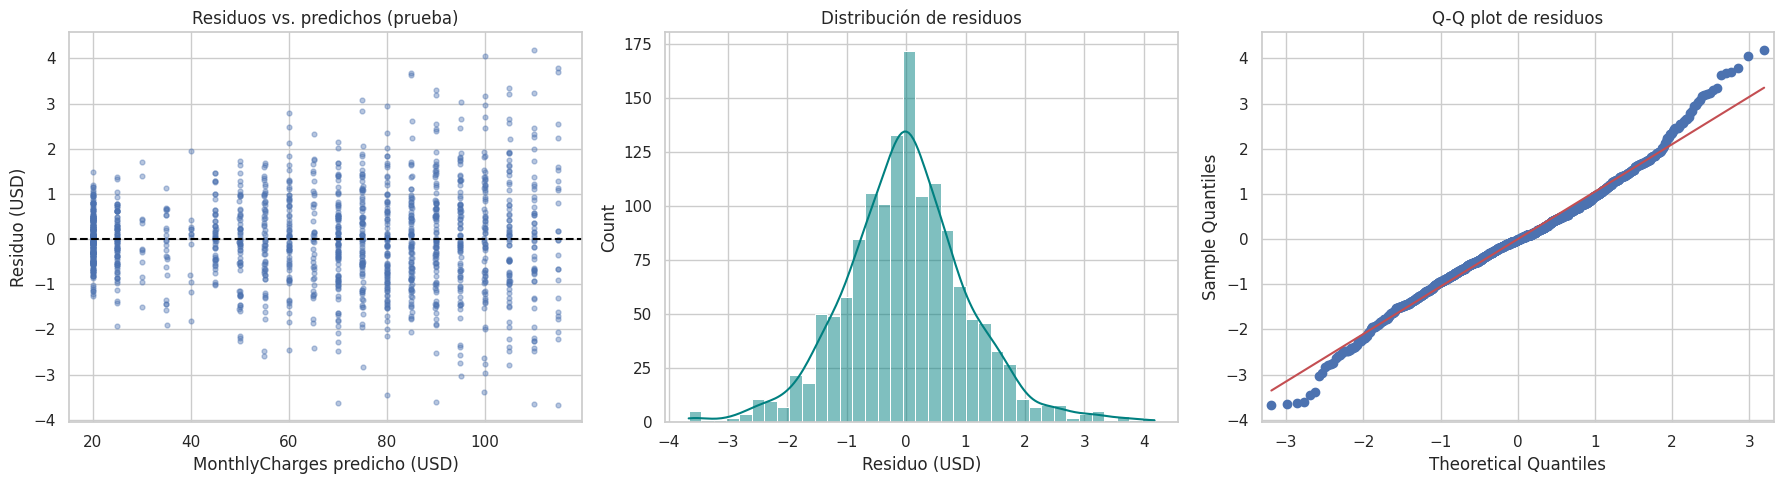

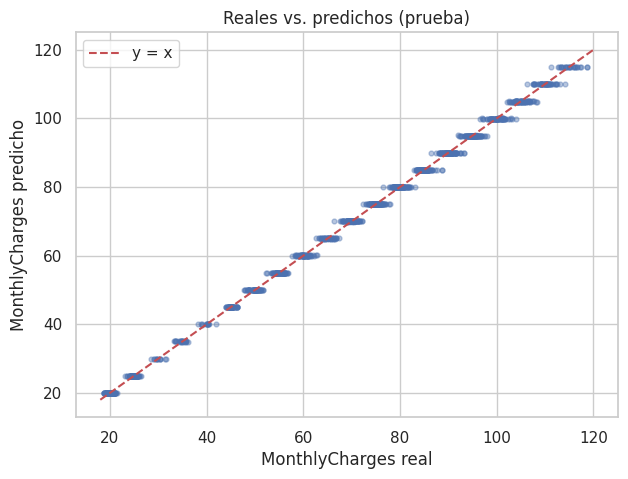

In [32]:
resid3_te = y3_te - pred3_te
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(pred3_te, resid3_te, alpha=0.4, s=12)
ax[0].axhline(0, color="black", ls="--")
ax[0].set(title="Residuos vs. predichos (prueba)", xlabel="MonthlyCharges predicho (USD)", ylabel="Residuo (USD)")
sns.histplot(resid3_te, kde=True, ax=ax[1], color="teal"); ax[1].set(title="Distribución de residuos", xlabel="Residuo (USD)")
sm.qqplot(resid3_te, line="s", ax=ax[2]); ax[2].set_title("Q-Q plot de residuos")
plt.tight_layout(); plt.show()

ax = plt.figure(figsize=(7, 5)).gca()
ax.scatter(y3_te, pred3_te, alpha=0.4, s=12); ax.plot([18, 120], [18, 120], "r--", label="y = x")
ax.set(xlabel="MonthlyCharges real", ylabel="MonthlyCharges predicho", title="Reales vs. predichos (prueba)"); ax.legend(); plt.show()

## 3.7 Heterogeneidad por segmento

,n,R2,MAE,RMSE,Desv. residuos,Desv. del objetivo
InternetService,,,,,,
DSL,482,0.995,0.840,1.089,1.089,15.525
Fiber optic,615,0.991,0.933,1.205,1.205,12.775
No,312,0.935,0.425,0.539,0.540,2.115


,n,R2,MAE,RMSE,Desv. residuos,Desv. del objetivo
Contract,,,,,,
Month-to-month,792,0.999,0.757,0.998,0.998,26.721
One year,261,0.999,0.839,1.103,1.100,31.894
Two year,356,0.999,0.823,1.123,1.124,35.054


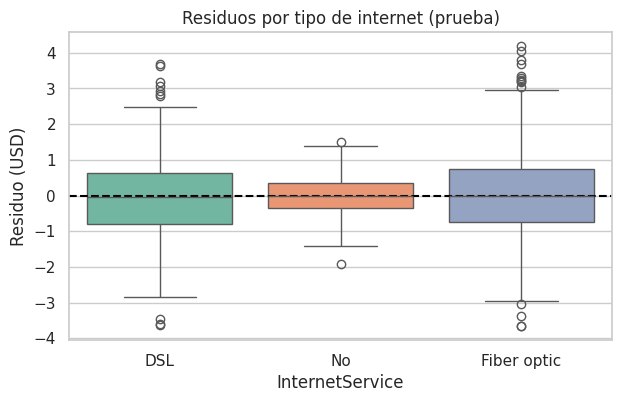

In [33]:
seg = telco.loc[X3_te.index]
for var in ["InternetService", "Contract"]:
    filas = []
    for g, idx in seg.groupby(var).groups.items():
        filas.append({var: g, "n": len(idx), **metricas(y3_te[idx], pred3_te[X3_te.index.get_indexer(idx)]),
                      "Desv. residuos": resid3_te[idx].std(), "Desv. del objetivo": y3_te[idx].std()})
    display(pd.DataFrame(filas).set_index(var).round(3))

plt.figure(figsize=(7, 4))
sns.boxplot(x=seg["InternetService"], y=resid3_te, palette="Set2")
plt.axhline(0, color="black", ls="--"); plt.title("Residuos por tipo de internet (prueba)"); plt.ylabel("Residuo (USD)"); plt.show()

### Heterogeneidad
* **Por tipo de internet:** el MAE es menor en clientes sin internet (≈ 0,43 USD) que en DSL (≈ 0,84) o fibra (≈ 0,93). Sin embargo, el R² de "sin internet" es el más bajo (0,935). No es contradictorio: en ese grupo los cargos casi no varían (desviación de 2,1 USD), así que hay muy poca variación que explicar y cualquier error pequeño pesa mucho en el R². **Por eso, para comparar subgrupos me fijo en el MAE/RMSE y no en el R².**
* La dispersión de los residuos aumenta con el precio: ±0,5 USD sin internet frente a ±1,2 USD en fibra. El modelo no tiene un sesgo por grupo (los residuos están centrados en 0), pero sí **más incertidumbre en los planes caros**, probablemente por descuentos o promociones que no están en el dataset.
* **Por contrato:** las métricas son prácticamente iguales en los tres tipos (MAE entre 0,76 y 0,84). El contrato **no** genera un comportamiento distinto en la tarifa.

## 3.8 Preguntas de cierre

**(a) Interpretación de un coeficiente con sus unidades**
El coeficiente de `Fiber` es **≈ 50,0 USD/mes**: con los mismos servicios adicionales, un cliente con fibra óptica paga en promedio 50 USD más al mes que un cliente sin internet (la categoría base). DSL suma ≈ 25 USD, el teléfono ≈ 20 USD, cada servicio de streaming ≈ 10 USD y cada servicio de seguridad, respaldo, protección, soporte o línea múltiple ≈ 5 USD. El modelo prácticamente **reconstruye la lista de precios** de la compañía, y el intercepto (≈ −0,08 USD) queda casi en 0, lo que tiene sentido: un cliente sin servicios no paga nada.

Además, al agregar `tenure`, contrato y variables demográficas el R² de prueba no cambia (0,99878 en ambos casos) y sus coeficientes son ≈ 0. La correlación de 0,25 entre `tenure` y el cargo era **indirecta**: los clientes antiguos tienen más servicios contratados, pero la antigüedad por sí sola no cambia el precio.

**(b) Error en entrenamiento vs. prueba**
| Conjunto | R² | MAE | RMSE |
| :--- | :---: | :---: | :---: |
| Entrenamiento | 0,9989 | 0,78 USD | 1,02 USD |
| Prueba | 0,9988 | 0,79 USD | 1,05 USD |

La diferencia es de apenas 0,01 USD en MAE y 0,03 USD en RMSE. Esto indica que el modelo **generaliza bien y no hay sobreajuste**: con solo 10 predictores y más de 5.600 filas de entrenamiento, no tiene capacidad para "memorizar" los datos. El error de ≈ 0,8 USD es menos del 2 % del cargo promedio (≈ 65 USD).

¿Se puede confiar en un R² de 0,999? En este caso sí, porque revisé el leakage: el modelo no usa ninguna variable derivada del cargo, solo los servicios que se conocen antes de facturar. El R² es alto porque la tarifa realmente es una **suma de precios por servicio**, que es justo lo que modela una regresión lineal.

**(c) Supuesto de la regresión lineal: cumplido e incumplido**
* ✅ **Linealidad — se cumple.** En el gráfico de residuos vs. predichos los residuos están centrados en 0 en todo el rango de precios, sin forma de curva (a diferencia del modelo de área del Bloque 1). Esto es esperable porque el cargo es aditivo.
* ❌ **Homocedasticidad (varianza constante) — se incumple.** El mismo gráfico tiene forma de **embudo**: con predicciones cercanas a 20 USD los residuos están entre ±1,5 USD, y cerca de 100 USD llegan a ±4 USD. La tabla por tipo de internet lo confirma (desviación de los residuos 0,54 USD sin internet vs. 1,21 USD con fibra). Además, el Q-Q plot muestra que las colas de los residuos se separan de la línea normal, así que la normalidad tampoco se cumple completamente en los extremos. En la práctica, las predicciones siguen siendo buenas, pero el margen de error de los planes caros es mayor que el de los planes baratos.

---
## 🧾 Conclusión general
| Bloque | Modelo | R² prueba | ¿Se puede confiar? |
| :--- | :--- | :---: | :--- |
| 1 | `perimeter_mean ~ radius_mean` | 0,996 | **Sí**: residuos aleatorios, relación lineal real (P = 2πr). |
| 1 | `area_mean ~ radius_mean` | 0,981 | **No del todo**: R² alto pero residuos en U; la relación es cuadrática. |
| 2 | `Overall ~ 9 atributos` | 0,777 | **Con reservas**: sin leakage ni multicolinealidad, pero subestima sistemáticamente a los arqueros (heterogeneidad). |
| 3 | `MonthlyCharges ~ servicios` | 0,999 | **Sí**: sin leakage, generaliza bien y recupera la lista de precios; su única debilidad es la varianza creciente en planes caros. |

Lo más importante que aprendí es que el R² no basta para evaluar un modelo. En el Bloque 1 dos modelos con R² parecido eran muy distintos al mirar los residuos; en el Bloque 2 el modelo global escondía un sesgo en un grupo de jugadores; y en el Bloque 3 un R² de 0,999 era creíble solo después de descartar `TotalCharges`, que habría producido el mismo número pero con un modelo inútil en la práctica.

---
## Declaración de autoría y uso de herramientas
* **Autor:** Jose Martin Labarca Aguileta · IEI097 Minería de Datos · Octubre 2026
* **Uso de IA generativa:** se utilizó **Claude (Anthropic)** como apoyo para estructurar el código en Python (descarga, gráficos, VIF y métricas), tal como permite la actividad. La selección de variables, las decisiones frente a leakage/multicolinealidad/heterogeneidad y las interpretaciones fueron revisadas y validadas por mí.


Link github https://github.com/josemartinlabarca/mineria-datos-churn-telco/blob/main/Lab_2_8_Regresion_Lineal.ipynb